# Study 2: EDI observation resolution

This experiment tests whether finer EDI observations help the trained policies continue beyond EDI 70. The reward, pollution equations, action space, seeds, exploration schedule, episode length, and training episode count stay fixed. Only EDI observation boundaries change.

## Settings and comparison design

The baseline uses EDI boundaries `(34, 67)`. The refined condition uses `(34, 67, 70, 80, 90, 100)`, giving separate observation bins for EDI 70?79, 80?89, 90?99, and 100. All other configuration values come from the existing `EnvironmentConfig` and `TrainingConfig`. Both conditions use the same five training seeds and twenty held-out evaluation seeds.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from study_2_economic_sustainability.config import EnvironmentConfig, TrainingConfig
from study_2_economic_sustainability.environment import ACTION_NAMES, ACTION_SPECS, EconomicSustainabilityEnvironment
from study_2_economic_sustainability.evaluation import run_episode
from study_2_economic_sustainability.train import load_q_tables, save_q_tables, train_agents

In [2]:
REWARD_MODES = ('local', 'global', 'mixed')
BASELINE_RESULTS = '../results/reward_candidate'
REFINED_RESULTS = '../results/edi_resolution'
RUN_TRAINING = False

baseline_config = EnvironmentConfig()
refined_config = EnvironmentConfig()
refined_config.edi_observation_boundaries = (34, 67, 70, 80, 90, 100)
training_config = TrainingConfig()
TRAINING_SEEDS = training_config.training_seeds
EVALUATION_SEEDS = training_config.evaluation_seeds

settings = {
    'reward_formula': 'candidate',
    'baseline_edi_observation_boundaries': baseline_config.edi_observation_boundaries,
    'refined_edi_observation_boundaries': refined_config.edi_observation_boundaries,
    'baseline_environment': baseline_config.__dict__,
    'refined_environment': refined_config.__dict__,
    'training': training_config.__dict__,
    'reward_modes': REWARD_MODES,
    'training_seeds': TRAINING_SEEDS,
    'evaluation_seeds': EVALUATION_SEEDS,
}

In [3]:
with open(f'{REFINED_RESULTS}/settings.json', 'w', encoding='utf-8') as file:
    json.dump(settings, file, indent=2)
    file.write('\n')

settings_summary = pd.DataFrame([
    {'condition': 'baseline', 'EDI_boundaries': baseline_config.edi_observation_boundaries},
    {'condition': 'refined', 'EDI_boundaries': refined_config.edi_observation_boundaries},
])
display(settings_summary)

,condition,EDI_boundaries
0,baseline,"(34, 67)"
1,refined,"(34, 67, 70, 80, 90, 100)"


## Train the refined observation condition

Train the same three reward modes using the existing five training seeds and 2,000 episodes per seed and mode. The candidate reward and all pollution and economic equations remain fixed. The completed Q-tables are loaded by default (`RUN_TRAINING = False`); set it to `True` to repeat the training run.

In [4]:
if RUN_TRAINING:
    refined_policies = {}

    for reward_mode in REWARD_MODES:
        for training_seed in TRAINING_SEEDS:
            agents = train_agents(
                reward_mode,
                training_seed,
                refined_config,
                training_config,
            )
            refined_policies[(reward_mode, training_seed)] = agents
            print(f'Trained {reward_mode} reward, seed {training_seed}')

    save_q_tables(refined_policies, REFINED_RESULTS, notebook_number=18)
else:
    refined_policies = load_q_tables(
        REWARD_MODES, TRAINING_SEEDS, training_config,
        REFINED_RESULTS, notebook_number=18,
    )

baseline_policies = load_q_tables(
    REWARD_MODES,
    TRAINING_SEEDS,
    training_config,
    BASELINE_RESULTS,
    notebook_number=3,
)

## Evaluate matched policies and count development actions

Replay both conditions on the same held-out seeds. Development-action frequency is the fraction of regional decisions in a specified EDI band that select a development action. Frequencies above EDI 70 are the key diagnostic; spending and pollution are computed from the resulting trajectories.

In [5]:
def summarize_episode(environment, agents, seed, condition, reward_mode, training_seed):
    transitions, terminated, truncated = run_episode(environment, agents, seed)
    gpi_values = []
    prevention_spending = 0.0
    cleanup_spending = 0.0
    band_decisions = {'70_79': 0, '80_89': 0, '90_99': 0, '100': 0}
    band_development = {band: 0 for band in band_decisions}
    band_valid_development = {band: 0 for band in band_decisions}
    development_above_70 = 0
    decisions_above_70 = 0
    valid_development_above_70 = 0

    for transition in transitions:
        info = transition['info']
        gpi_values.append(info['global_pollution_index'])
        prevention_spending += sum(info['prevention_costs_paid'])
        cleanup_spending += sum(info['cleanup_costs_paid'])

        for region in environment.config.regions:
            edi = transition['development_before'][region]
            action = transition['actions'][region]
            is_development = ACTION_SPECS[action][0] == 1
            is_valid = info['valid_actions'][region]

            if edi >= 70:
                decisions_above_70 += 1
                development_above_70 += is_development
                valid_development_above_70 += is_development and is_valid

            if 70 <= edi < 80:
                band = '70_79'
            elif 80 <= edi < 90:
                band = '80_89'
            elif 90 <= edi < 100:
                band = '90_99'
            elif edi >= 100:
                band = '100'
            else:
                continue

            band_decisions[band] += 1
            band_development[band] += is_development
            band_valid_development[band] += is_development and is_valid

    row = {
        'condition': condition,
        'reward_mode': reward_mode,
        'training_seed': training_seed,
        'evaluation_seed': seed,
        'steps': len(transitions),
        'failure': terminated,
        'mean_gpi': np.mean(gpi_values),
        'final_mean_edi': np.mean(environment.development_indices),
        'prevention_spending': prevention_spending,
        'cleanup_spending': cleanup_spending,
        'mitigation_spending': prevention_spending + cleanup_spending,
        'decisions_above_70': decisions_above_70,
        'development_actions_above_70': development_above_70,
        'valid_development_actions_above_70': valid_development_above_70,
        'development_frequency_above_70': development_above_70 / decisions_above_70 if decisions_above_70 else np.nan,
        'valid_development_frequency_above_70': valid_development_above_70 / decisions_above_70 if decisions_above_70 else np.nan,
    }

    for band in band_decisions:
        row[f'decisions_{band}'] = band_decisions[band]
        row[f'development_actions_{band}'] = band_development[band]
        row[f'development_frequency_{band}'] = band_development[band] / band_decisions[band] if band_decisions[band] else np.nan
        row[f'valid_development_frequency_{band}'] = band_valid_development[band] / band_decisions[band] if band_decisions[band] else np.nan

    return row

In [6]:
episode_rows = []
conditions = (('baseline', baseline_config, baseline_policies), ('refined', refined_config, refined_policies))

for condition, environment_config, policies in conditions:
    for (reward_mode, training_seed), agents in policies.items():
        environment = EconomicSustainabilityEnvironment(reward_mode, environment_config, reward_formula='candidate')
        for evaluation_seed in EVALUATION_SEEDS:
            episode_rows.append(summarize_episode(environment, agents, evaluation_seed, condition, reward_mode, training_seed))

comparison_episodes = pd.DataFrame(episode_rows)
comparison_episodes.to_csv(f'{REFINED_RESULTS}/matched_evaluation_episodes.csv', index=False)
display(comparison_episodes.head())

,condition,reward_mode,training_seed,evaluation_seed,steps,failure,mean_gpi,final_mean_edi,prevention_spending,cleanup_spending,...,development_frequency_80_89,valid_development_frequency_80_89,decisions_90_99,development_actions_90_99,development_frequency_90_99,valid_development_frequency_90_99,decisions_100,development_actions_100,development_frequency_100,valid_development_frequency_100
0,baseline,local,11,200000,200,False,9.943213,70.0,4390.0,12135.0,...,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN
1,baseline,local,11,200001,200,False,8.892857,70.0,4875.0,12920.0,...,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN
2,baseline,local,11,200002,200,False,8.518465,70.0,4240.0,13230.0,...,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN
3,baseline,local,11,200003,200,False,9.107217,70.0,4710.0,12830.0,...,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN
4,baseline,local,11,200004,200,False,9.850342,70.0,4530.0,12155.0,...,NaN,NaN,0,0,NaN,NaN,0,0,NaN,NaN


## Compare outcomes

First average the twenty held-out episodes within each training seed. The final table then summarizes the five training-seed results, so the independent training runs remain the unit of comparison. Positive EDI and development-frequency changes favor the refined observation; negative GPI and mitigation-spending changes indicate lower values.

In [7]:
metric_columns = [
    'failure', 'mean_gpi', 'final_mean_edi', 'mitigation_spending',
    'development_frequency_above_70',
    'valid_development_frequency_above_70',
    'development_frequency_70_79',
    'development_frequency_80_89',
    'development_frequency_90_99',
]

per_training_seed = comparison_episodes.groupby(['condition', 'reward_mode', 'training_seed'], sort=False)[metric_columns].mean().reset_index()
per_training_seed.to_csv(f'{REFINED_RESULTS}/per_training_seed.csv', index=False)

In [8]:
comparison_summary = per_training_seed.groupby(['condition', 'reward_mode'], sort=False)[metric_columns].agg(['mean', 'std'])
display(comparison_summary.round(3))

failure      mean_gpi        final_mean_edi         \
                         mean  std     mean    std           mean    std   
condition reward_mode                                                      
baseline  local           0.0  0.0   10.435  4.729         69.988  0.028   
          global          0.0  0.0    5.337  1.171         70.000  0.000   
          mixed           0.0  0.0    6.579  2.053         70.000  0.000   
refined   local           0.0  0.0   14.854  2.009         99.708  0.654   
          global          0.0  0.0    9.021  4.247         98.605  1.666   
          mixed           0.0  0.0   12.231  3.316         99.995  0.011   

                      mitigation_spending            \
                                     mean       std   
condition reward_mode                                 
baseline  local                  16565.15  4664.042   
          global                 26066.55  4467.912   
          mixed                  21864.10  5019.546   
refined   local                  18425.70  2270.164   
          global                 28064.85  8267.977   
          mixed                  19904.45  3542.848   

                      development_frequency_above_70         \
                                                mean    std   
condition reward_mode                                         
baseline  local                                0.000  0.000   
          global                               0.000  0.000   
          mixed                                0.000  0.000   
refined   local                                0.082  0.001   
          global                               0.085  0.004   
          mixed                                0.083  0.000   

                      valid_development_frequency_above_70         \
                                                      mean    std   
condition reward_mode                                               
baseline  local                                      0.000  0.000   
          global                                     0.000  0.000   
          mixed                                      0.000  0.000   
refined   local                                      0.082  0.001   
          global                                     0.084  0.004   
          mixed                                      0.083  0.000   

                      development_frequency_70_79         \
                                             mean    std   
condition reward_mode                                      
baseline  local                             0.000  0.000   
          global                            0.000  0.000   
          mixed                             0.000  0.000   
refined   local                             0.432  0.021   
          global                            0.344  0.034   
          mixed                             0.428  0.026   

                      development_frequency_80_89         \
                                             mean    std   
condition reward_mode                                      
baseline  local                               NaN    NaN   
          global                              NaN    NaN   
          mixed                               NaN    NaN   
refined   local                             0.424  0.040   
          global                            0.401  0.080   
          mixed                             0.425  0.022   

                      development_frequency_90_99         
                                             mean    std  
condition reward_mode                                     
baseline  local                               NaN    NaN  
          global                              NaN    NaN  
          mixed                               NaN    NaN  
refined   local                             0.369  0.061  
          global                            0.377  0.169  
          mixed                             0.420  0.035

In [9]:
paired = per_training_seed.pivot(index=['reward_mode', 'training_seed'], columns='condition', values=metric_columns)
delta_rows = []
for reward_mode in REWARD_MODES:
    subset = paired.loc[reward_mode]
    for metric in metric_columns:
        if (metric, 'refined') not in subset.columns:
            continue
        difference = subset[(metric, 'refined')] - subset[(metric, 'baseline')]
        delta_rows.append({
            'reward_mode': reward_mode,
            'metric': metric,
            'mean_paired_change': difference.mean(),
            'sd_across_training_seeds': difference.std(),
        })

paired_changes = pd.DataFrame(delta_rows)
paired_changes.to_csv(f'{REFINED_RESULTS}/paired_changes.csv', index=False)
display(paired_changes.pivot(index='metric', columns='reward_mode', values='mean_paired_change').round(3))

reward_mode,global,local,mixed
metric,,,
development_frequency_70_79,0.344,0.432,0.428
development_frequency_80_89,NaN,NaN,NaN
development_frequency_90_99,NaN,NaN,NaN
development_frequency_above_70,0.085,0.082,0.083
failure,0.000,0.000,0.000
final_mean_edi,28.605,29.720,29.995
mean_gpi,3.684,4.418,5.652
mitigation_spending,1998.300,1860.550,-1959.650
valid_development_frequency_above_70,0.084,0.082,0.083


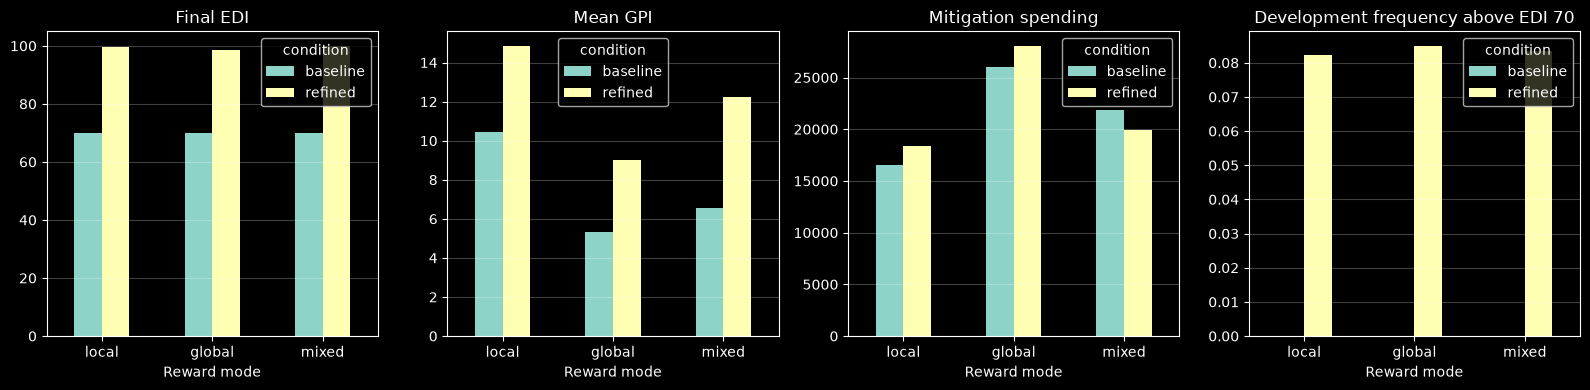

In [10]:
plot_metrics = ['final_mean_edi', 'mean_gpi', 'mitigation_spending', 'development_frequency_above_70']
plot_labels = ['Final EDI', 'Mean GPI', 'Mitigation spending', 'Development frequency above EDI 70']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for axis, metric, label in zip(axes, plot_metrics, plot_labels):
    values = per_training_seed.groupby(['condition', 'reward_mode'], sort=False)[metric].mean().unstack('condition')
    values.plot(kind='bar', ax=axis, rot=0)
    axis.set_title(label)
    axis.set_xlabel('Reward mode')
    axis.grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

## Findings

The refined EDI observations removed the EDI 70 plateau in all three reward modes. Baseline mean final EDI was 69.99?70.00 with zero development actions above 70. With the refined bins, mean final EDI was 98.61 for global, 99.71 for local, and 100.00 for mixed reward (standard deviations across training seeds: 1.67, 0.65, and 0.01). All four regions finished at EDI 100 in 72, 97, and 99 of the 100 evaluation episodes for global, local, and mixed reward, respectively. No episode failed environmentally.

Development decisions occurred in every added band: mean development-action frequency was 34?43% in EDI 70?79, 40?43% in EDI 80?89, and 37?42% in EDI 90?99. Overall, development was selected in about 8% of decisions above EDI 70, compared with zero in the baseline. The agents continued developing when the observation could distinguish progress through the high-EDI range.

Mean GPI increased in all modes: global rose from 5.34 to 9.02, local from 10.44 to 14.85, and mixed from 6.58 to 12.23. Mean mitigation spending rose from 26,067 to 28,065 for global and from 16,565 to 18,426 for local. Mixed reward reached almost EDI 100 while mitigation spending fell from 21,864 to 19,904. Pollution stayed below the failure threshold in every episode.

This comparison supports coarse EDI discretization as a major reason for the earlier stopping behavior: finer observations let agents distinguish progress beyond EDI 70 without changing rewards or pollution dynamics. It also shows a tradeoff, since mean GPI increased. The refined condition changes the observation-state count as part of the hypothesis, so this does not establish that discretization was the only possible contributor.